# Polynomial Regression - Plain, Ridge and Lasso (picks the best model from YOUR data)

This notebook trains polynomial regression models on your own assignment data and creates your prediction files. The best degree and alpha are chosen from your data, so your final model and numbers will be your own.

**How to use it:** run the cells from top to bottom (click a cell, press **Shift + Enter**). Do not skip cells.
Run the whole notebook once with `VAR = 1`, then change it to `VAR = 2` (Step 3) and run it again from Step 3 down.

**Words used here, in simple language**
- **Polynomial regression**: fitting a curve like `a + b*x1 + c*x1^2 + d*x1*x2 + ...` to the data. *Degree* is the highest total power allowed.
- **MSE** (mean squared error): average of (prediction - real y) squared. **Lower is better.**
- **R2**: how much of the variation in y the model explains. 1.0 is perfect. **Higher is better.**
- **Plain**: ordinary least squares, finds the best coefficients with no extra rules.
- **Ridge**: same, but large coefficients are penalised. `alpha` is the strength of the penalty.
- **Lasso**: same, but the penalty pushes many coefficients to exactly 0, so only the useful terms stay.
- **Cross-validation (CV)**: split the training rows into 5 parts, train on 4, test on the 5th, repeat 5 times.
  This tells us how the model behaves on data it has not seen, without ever touching the test file.

## Step 1 - Import the libraries

In [58]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
print("libraries loaded")

libraries loaded


## Step 2 - Upload your 4 data files
When you run this cell, a **Choose files** button appears. Select all four files, of training and test datasets of var1 and var2


In [59]:
try:
    from google.colab import files
    uploaded = files.upload()
    print("uploaded:", list(uploaded.keys()))
except ImportError:
    print("Not running in Colab - using the csv files in the current folder")

Saving BT2024026_test_var1.csv to BT2024026_test_var1 (4).csv
Saving BT2024026_test_var2.csv to BT2024026_test_var2 (4).csv
Saving BT2024026_train_var1.csv to BT2024026_train_var1 (4).csv
Saving BT2024026_train_var2.csv to BT2024026_train_var2 (4).csv
uploaded: ['BT2024026_test_var1 (4).csv', 'BT2024026_test_var2 (4).csv', 'BT2024026_train_var1 (4).csv', 'BT2024026_train_var2 (4).csv']


## Step 3 - Choose the problem
`VAR = 1` is the turbine problem (6 inputs). `VAR = 2` is the underground heat map problem (3 inputs).

In [60]:
ROLL = "BT2024026"     # must match the start of your csv file names
VAR = 1        # change to 2 for the second problem, then run from this cell downwards

## Step 4 - Load the data and look at it
`y` is the target. Every other column is an input. The test file has no `y`.

In [61]:
train = pd.read_csv(f"{ROLL}_train_var{VAR}.csv")
test = pd.read_csv(f"{ROLL}_test_var{VAR}.csv")

features = [c for c in train.columns if c != "y"]   # all columns except y
X = train[features].values
y = train["y"].values

print("input columns:", features)
print("train rows:", len(train), "| test rows:", len(test))
print("missing values in train:", int(train.isna().sum().sum()))
train.head()

input columns: ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
train rows: 1000 | test rows: 1000
missing values in train: 0


,x1,x2,x3,x4,x5,x6,y
0,-0.579089,-0.393198,0.361449,-0.124276,1.000000,0.128578,1.266616
1,0.705959,-0.360027,0.260637,-0.701654,0.036911,-1.000000,4.925006
2,-1.000000,0.288548,-0.056055,0.390098,1.000000,-0.478273,3.475065
3,1.000000,0.337354,0.104215,0.290797,1.000000,0.312023,-2.785383
4,-1.000000,-1.000000,-0.166205,-0.474129,1.000000,0.652830,1.544224


## Step 5 - Two helper functions
1. `build_model` makes a polynomial model of a given method (`plain`, `ridge` or `lasso`), degree and alpha.
2. `cv_score` measures how good a model is using cross-validation (3 different shuffles, averaged).

In [62]:
def build_model(method, degree, alpha=0.0):
    if method == "plain":
        return make_pipeline(PolynomialFeatures(degree), LinearRegression())
    if method == "ridge":
        penalty = Ridge(alpha=alpha)
    else:
        penalty = Lasso(alpha=alpha, max_iter=20000, tol=1e-4)
    # standardise the polynomial terms so the penalty treats them fairly
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), penalty)


def cv_score(method, degree, alpha=0.0, seeds=(0, 1, 2)):
    mses, r2s = [], []
    for seed in seeds:
        kf = KFold(n_splits=5, shuffle=True, random_state=seed)
        pred = cross_val_predict(build_model(method, degree, alpha), X, y, cv=kf)
        mses.append(mean_squared_error(y, pred))
        r2s.append(r2_score(y, pred))
    return np.mean(mses), np.mean(r2s)

print("helper functions ready")

helper functions ready


## Step 6 - Settings to try
These are the degrees and alpha values the notebook will test. Each problem has its own list.
The lists are wide on purpose, because the best degree is different for every dataset.

In [63]:
if VAR == 1:
    plain_degrees = range(1, 7)
    ridge_degrees, ridge_alphas = [3, 4, 5, 6, 7], [1, 3, 10, 30, 100, 300]
    lasso_degrees, lasso_alphas = [4, 5, 6, 7], [0.005, 0.01, 0.02, 0.04]
else:
    plain_degrees = range(1, 15)
    ridge_degrees, ridge_alphas = [8, 9, 10, 11, 12, 13], [0.1, 0.3, 1, 3, 10]
    lasso_degrees, lasso_alphas = [9, 10, 11], [0.0003, 0.001, 0.003]

rows = []     # every result is stored here
print("settings ready for var", VAR)

settings ready for var 1


## Step 7 - Train and test PLAIN polynomial regression
For each degree: build the model, run cross-validation, store the MSE and R2.
Watch what happens as the degree grows: the error first falls (the model learns the shape), then rises again (overfitting).

In [64]:
for degree in plain_degrees:
    mse, r2 = cv_score("plain", degree)
    rows.append(("plain", degree, 0.0, mse, r2))
    print(f"plain  degree {degree:2d}   CV MSE {mse:12.4f}   R2 {r2:9.4f}")

plain  degree  1   CV MSE       9.1652   R2    0.0937
plain  degree  2   CV MSE       3.1918   R2    0.6844
plain  degree  3   CV MSE       1.0167   R2    0.8995
plain  degree  4   CV MSE       0.8071   R2    0.9202
plain  degree  5   CV MSE       1.4034   R2    0.8612
plain  degree  6   CV MSE    1564.0379   R2 -153.6609


## Step 8 - Train and test RIDGE
Same idea, but now for every degree we also try several alpha values.

In [65]:
for degree in ridge_degrees:
    for alpha in ridge_alphas:
        mse, r2 = cv_score("ridge", degree, alpha)
        rows.append(("ridge", degree, alpha, mse, r2))
        print(f"ridge  degree {degree:2d}  alpha {alpha:7g}   CV MSE {mse:9.4f}   R2 {r2:8.4f}")

ridge  degree  3  alpha       1   CV MSE    1.0149   R2   0.8996
ridge  degree  3  alpha       3   CV MSE    1.0122   R2   0.8999
ridge  degree  3  alpha      10   CV MSE    1.0099   R2   0.9001
ridge  degree  3  alpha      30   CV MSE    1.0307   R2   0.8981
ridge  degree  3  alpha     100   CV MSE    1.2027   R2   0.8811
ridge  degree  3  alpha     300   CV MSE    1.8183   R2   0.8202
ridge  degree  4  alpha       1   CV MSE    0.7846   R2   0.9224
ridge  degree  4  alpha       3   CV MSE    0.7585   R2   0.9250
ridge  degree  4  alpha      10   CV MSE    0.7298   R2   0.9278
ridge  degree  4  alpha      30   CV MSE    0.7459   R2   0.9262
ridge  degree  4  alpha     100   CV MSE    0.8773   R2   0.9132
ridge  degree  4  alpha     300   CV MSE    1.1819   R2   0.8831
ridge  degree  5  alpha       1   CV MSE    0.7914   R2   0.9217
ridge  degree  5  alpha       3   CV MSE    0.6219   R2   0.9385
ridge  degree  5  alpha      10   CV MSE    0.5223   R2   0.9484
ridge  degree  5  alpha  

## Step 9 - Train and test LASSO
Lasso can take a minute or two. Please wait until the cell finishes (a number appears in the brackets on the left).

In [66]:
for degree in lasso_degrees:
    for alpha in lasso_alphas:
        mse, r2 = cv_score("lasso", degree, alpha)
        rows.append(("lasso", degree, alpha, mse, r2))
        print(f"lasso  degree {degree:2d}  alpha {alpha:7g}   CV MSE {mse:9.4f}   R2 {r2:8.4f}")

lasso  degree  4  alpha   0.005   CV MSE    0.6593   R2   0.9348
lasso  degree  4  alpha    0.01   CV MSE    0.6529   R2   0.9354
lasso  degree  4  alpha    0.02   CV MSE    0.6826   R2   0.9325
lasso  degree  4  alpha    0.04   CV MSE    0.7593   R2   0.9249
lasso  degree  5  alpha   0.005   CV MSE    0.3570   R2   0.9647
lasso  degree  5  alpha    0.01   CV MSE    0.3468   R2   0.9657
lasso  degree  5  alpha    0.02   CV MSE    0.3617   R2   0.9642
lasso  degree  5  alpha    0.04   CV MSE    0.4444   R2   0.9561
lasso  degree  6  alpha   0.005   CV MSE    0.3715   R2   0.9633
lasso  degree  6  alpha    0.01   CV MSE    0.3580   R2   0.9646
lasso  degree  6  alpha    0.02   CV MSE    0.3713   R2   0.9633
lasso  degree  6  alpha    0.04   CV MSE    0.4565   R2   0.9549
lasso  degree  7  alpha   0.005   CV MSE    0.3907   R2   0.9614
lasso  degree  7  alpha    0.01   CV MSE    0.3688   R2   0.9635
lasso  degree  7  alpha    0.02   CV MSE    0.3780   R2   0.9626
lasso  degree  7  alpha  

## Step 10 - Compare the three methods
The table shows the best model of each method (lowest CV MSE). The chart shows CV MSE for every model tried.

Best model of each method:


,method,degree,alpha,cv_mse,cv_r2
41,lasso,5,0.01,0.3468,0.9657
3,plain,4,0.00,0.8071,0.9202
21,ridge,5,30.00,0.5165,0.9489


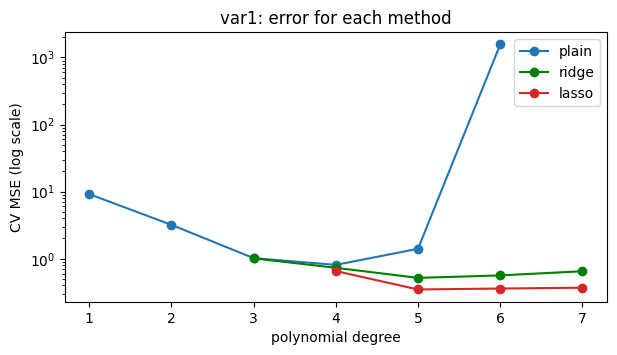

In [67]:
results = pd.DataFrame(rows, columns=["method", "degree", "alpha", "cv_mse", "cv_r2"])

best_per_method = results.loc[results.groupby("method")["cv_mse"].idxmin()]
print("Best model of each method:")
display(best_per_method.round(4))

plt.figure(figsize=(7, 3.5))
for m, color in (("plain", "tab:blue"), ("ridge", "green"), ("lasso", "tab:red")):
    sub = results[results.method == m]
    best_by_degree = sub.loc[sub.groupby("degree")["cv_mse"].idxmin()]
    plt.plot(best_by_degree["degree"], best_by_degree["cv_mse"], "o-", color=color, label=m)
plt.yscale("log")
plt.xlabel("polynomial degree")
plt.ylabel("CV MSE (log scale)")
plt.title(f"var{VAR}: error for each method")
plt.legend()
plt.show()

## Step 11 - Choose the final model
The notebook picks the model with the lowest CV MSE in the table above (the lowest error on data it has not seen).
Look at the table yourself: if several models are almost tied, a lower degree is the safer choice.
You can also type your own choice by changing the last line of the cell.

In [68]:
best = results.loc[results["cv_mse"].idxmin()]
method, degree, alpha = best["method"], int(best["degree"]), float(best["alpha"])

# method, degree, alpha = "lasso", 5, 0.01     # <- remove the # and edit this line to choose your own

print("final model:", method, "| degree", degree, "| alpha", alpha)

final model: lasso | degree 5 | alpha 0.01


## Step 12 - Train the final model on ALL training rows
Now there is no cross-validation. The model learns from all 1000 training rows.

In [69]:
final_model = build_model(method, degree, alpha)
final_model.fit(X, y)

train_pred = final_model.predict(X)
print("training MSE:", round(mean_squared_error(y, train_pred), 4))
print("training R2 :", round(r2_score(y, train_pred), 4))

if method == "lasso":
    coefs = final_model[-1].coef_
    print("polynomial terms kept by Lasso:", int(np.sum(coefs != 0)), "of", len(coefs))

training MSE: 0.2477
training R2 : 0.9755
polynomial terms kept by Lasso: 120 of 461


## Step 13 - Predict the test file and save the answer
The model predicts `y` for every row of the test file, in the same order. The result is saved as one column called `y`.

In [70]:
test_pred = final_model.predict(test[features].values)

out = pd.DataFrame({"y": test_pred})
out_name = f"{ROLL}_pred_var{VAR}.csv"
out.to_csv(out_name, index=False)

print("saved", out_name, "| rows:", len(out))
out.head()

saved BT2024026_pred_var1.csv | rows: 1000


,y
0,-0.795754
1,5.892638
2,1.467789
3,0.358453
4,-3.932072


## Step 14 - Download the prediction file
Run this cell to download the file to your computer. Then change `VAR = 2` in Step 3 and run Steps 3 to 14 again for the second file.

In [71]:
try:
    from google.colab import files
    files.download(out_name)
except ImportError:
    print("Not in Colab - the file is in the current folder:", out_name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>